In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import uproot
import matplotlib

In [2]:
def applyCut(inputDataframe, cut, text=None):
    dataframe = inputDataframe
    nbeforecut = dataframe.shape[0]
    cutDataframe = dataframe.query(cut)
    if text:
        print (text, cutDataframe.shape[0], ' fraction kept: %2.1f'%(100.0*float(cutDataframe.shape[0])/nbeforecut))
    return cutDataframe

def getData(observables, filename, treename):
    return (uproot.open(filename)[treename]).arrays(observables, library='pd')

def getRcAndErr(df, ob):
    if (ob == 'b'):
        nos = sum(df[df.b==-1]['w'])
        nss = sum(df[df.b==+1]['w'])
    elif (ob == 'b_ch'):
        nos = sum(df[df.b_ch==-1]['w'])
        nss = sum(df[df.b_ch==+1]['w'])
    elif (ob == 'bs'):
        nos = sum(df[df.bs==-1]['ws'])
        nss = sum(df[df.bs==+1]['ws'])
    else:
        print('Double check the input observable name!')
    rc = (nss-nos)/(nss+nos)
    p = nss/(nss+nos)
    w_array = np.unique(df['w'])
    err2_array = []
    variance_array_test = []
    for i in range(0, len(w_array)):
        if (ob == 'b'):
            p = sum(df[(df.w == w_array[i]) & (df.b==+1)]['w']) / sum(df[df.w == w_array[i]]['w'])
        elif (ob == 'b_ch'):
            p = sum(df[(df.w == w_array[i]) & (df.b_ch==+1)]['w']) / sum(df[df.w == w_array[i]]['w'])            
        elif (ob == 'bs'):
            p = sum(df[(df.w == w_array[i]) & (df.bs==+1)]['w']) / sum(df[df.w == w_array[i]]['ws'])
        else:
            print('Double check the input observable name!')        
        variance = p*(1-p)/df[df.w == w_array[i]].shape[0]
        w = sum(df[df.w == w_array[i]]['w'])/sum(df['w'])
        err2_array.append ( w**2*variance )
    rc_err = 2*np.sqrt(sum(err2_array))
    return rc, rc_err

def calc_hist(vals, bins=10, weights=None, density=False):    
    if weights is None:
        weights = np.ones(vals.shape)
    hist, bins = np.histogram(vals, bins=bins, weights=weights)
    digits = np.digitize(vals, bins)
    errs = np.asarray([np.linalg.norm(weights[digits==i]) for i in range(1, len(bins))])
    if density:
        density_int = weights.sum() * (bins[1] - bins[0])
        hist /= density_int
        errs /= density_int
    return hist, errs, bins

In [3]:
observables1 = ['pt','b','w','y1','y2','phi1','phi2']
observabless1 = ['pts','bs','ws','y1s','y2s','phi1s','phi2s','nefs']

In [4]:
df_allreco = applyCut(getData(observables1+observabless1, '/vast/palmer/home.grace/ys668/output/run12/all050124_rc.root', "MatchedTree"),\
              'pts>15 and bs!=-9 and w<1')

In [5]:
print(max(df_allreco['nefs']))

0.89999920129776


In [6]:
distance1 = []
distance2 = []
for i in range(0,df_allreco.shape[0]):
    phi1small = min(df_allreco.iloc[i]['phi1'], df_allreco.iloc[i]['phi1s'])
    phi1large = max(df_allreco.iloc[i]['phi1'], df_allreco.iloc[i]['phi1s'])
    phi2small = min(df_allreco.iloc[i]['phi2'], df_allreco.iloc[i]['phi2s'])
    phi2large = max(df_allreco.iloc[i]['phi2'], df_allreco.iloc[i]['phi2s'])
    dphi1 = min(phi1large-phi1small, 6.283185307179586-(phi1large-phi1small))
    dphi2 = min(phi2large-phi2small, 6.283185307179586-(phi2large-phi2small))
    if (dphi1 > np.pi):
        print(df_allreco.iloc[i]['phi1'], df_allreco.iloc[i]['phi1s'], dphi1)
    distance1.append(np.sqrt(dphi1**2+(df_allreco.iloc[i]['y1']-df_allreco.iloc[i]['y1s'])**2))
    distance2.append(np.sqrt(dphi2**2+(df_allreco.iloc[i]['y2']-df_allreco.iloc[i]['y2s'])**2))
df_allreco['distance1'] = distance1
df_allreco['distance2'] = distance2

Process PYTHIA6+GEANT

In [7]:
df_match = applyCut(df_allreco, 'pt!=-9 and b!=-9 and distance1<0.02 and distance2<0.03')
df_allfake = applyCut(df_allreco, 'pt==-9 or b==-9 or distance1>0.02 or distance2>0.03')

In [8]:
print(df_match.shape[0], df_allfake.shape[0])

2651196 1443963


In [9]:
print(np.unique(df_match['bs']))

[-1  1]


In [10]:
df_allreco_pts_array = [ df_allreco[(df_allreco.pts>15) & (df_allreco.pts<20)],\
                       df_allreco[(df_allreco.pts>20) & (df_allreco.pts<25)],\
                       df_allreco[(df_allreco.pts>25) & (df_allreco.pts<30)],\
                       df_allreco[(df_allreco.pts>30) & (df_allreco.pts<40)],\
                       df_allreco[(df_allreco.pts>40) & (df_allreco.pts<60)]]

df_match_pts_array = [ df_match[(df_match.pts>15) & (df_match.pts<20)],\
                       df_match[(df_match.pts>20) & (df_match.pts<25)],\
                       df_match[(df_match.pts>25) & (df_match.pts<30)],\
                       df_match[(df_match.pts>30) & (df_match.pts<40)],\
                       df_match[(df_match.pts>40) & (df_match.pts<60)] ]

df_allfake_pts_array = [ df_allfake[(df_allfake.pts>15) & (df_allfake.pts<20)],\
                       df_allfake[(df_allfake.pts>20) & (df_allfake.pts<25)],\
                       df_allfake[(df_allfake.pts>25) & (df_allfake.pts<30)],\
                       df_allfake[(df_allfake.pts>30) & (df_allfake.pts<40)],\
                       df_allfake[(df_allfake.pts>40) & (df_allfake.pts<60)]  ]

In [11]:
rc_allreco_bs_vs_pts_array = []
rc_err_allreco_bs_vs_pts_array = []
for i in range(0, len(df_allreco_pts_array)):
    rc_allreco_bs_vs_pts_array.append(getRcAndErr(df_allreco_pts_array[i], 'bs')[0])
    rc_err_allreco_bs_vs_pts_array.append(getRcAndErr(df_allreco_pts_array[i], 'bs')[1])
    
rc_match_bs_vs_pts_array = []
rc_err_match_bs_vs_pts_array = []
for i in range(0, len(df_match_pts_array)):
    rc_match_bs_vs_pts_array.append(getRcAndErr(df_match_pts_array[i], 'bs')[0])
    rc_err_match_bs_vs_pts_array.append(getRcAndErr(df_match_pts_array[i], 'bs')[1])

rc_allfake_bs_vs_pts_array = []
rc_err_allfake_bs_vs_pts_array = []
for i in range(0, len(df_allfake_pts_array)):
    rc_allfake_bs_vs_pts_array.append(getRcAndErr(df_allfake_pts_array[i], 'bs')[0])
    rc_err_allfake_bs_vs_pts_array.append(getRcAndErr(df_allfake_pts_array[i], 'bs')[1])

In [12]:
plt.rcParams['font.size'] = 12

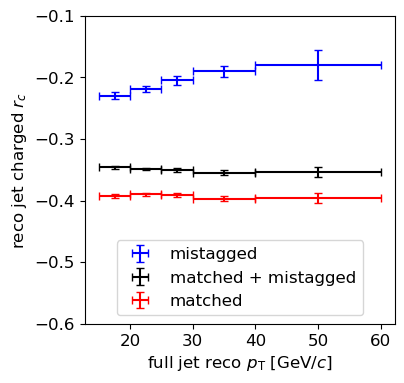

In [13]:
fig=plt.figure(figsize=(4,4))
plt.errorbar([17.5, 22.5, 27.5, 35, 50], rc_allfake_bs_vs_pts_array, xerr=[2.5, 2.5, 2.5, 5, 10], yerr=rc_err_allfake_bs_vs_pts_array, capsize=3, color='b', ls='none', label='mistagged')
plt.errorbar([17.5, 22.5, 27.5, 35, 50], rc_allreco_bs_vs_pts_array, xerr=[2.5, 2.5, 2.5, 5, 10], yerr=rc_err_allreco_bs_vs_pts_array, capsize=3, color='k', ls='none', label='matched + mistagged')
plt.errorbar([17.5, 22.5, 27.5, 35, 50], rc_match_bs_vs_pts_array, xerr=[2.5, 2.5, 2.5, 5, 10], yerr=rc_err_match_bs_vs_pts_array, capsize=3, color='r', ls='none', label='matched')
plt.xlabel('full jet reco $p_{\mathrm{T}}$ [GeV$/c$]')
plt.ylabel('reco jet charged $r_c$')
plt.ylim(-0.6,-0.1)
plt.legend(loc='lower center')

In [14]:
rc_allfake_bs_vs_pts_array

[-0.22960310036807838,
 -0.21930782279134386,
 -0.20501897201017164,
 -0.1901314941702848,
 -0.17961109455906574]

In [15]:
ob = 'b'
range_low = -1.2
range_high = 1.2
bins = 2

In [16]:
b_fake_array = []
for i in range(0,5):
    df_fake_pts = df_allfake_pts_array[i]
    y_fake_rec,yerr_fake_rec,x = calc_hist(df_fake_pts[ob+'s'], bins=np.arange(range_low,range_high+(range_high-range_low)/bins, (range_high-range_low)/bins), weights=df_fake_pts['ws'], density=True)
    b_fake_array.append(y_fake_rec/sum(y_fake_rec))

In [17]:
b_fake_array

[array([0.61480155, 0.38519845]),
 array([0.60965391, 0.39034609]),
 array([0.60250949, 0.39749051]),
 array([0.59506575, 0.40493425]),
 array([0.58980555, 0.41019445])]

In [18]:
df_match_pt_array = [ df_match[(df_match.pt>15) & (df_match.pt<20)],\
                       df_match[(df_match.pt>20) & (df_match.pt<25)],\
                       df_match[(df_match.pt>25) & (df_match.pt<30)],\
                       df_match[(df_match.pt>30) & (df_match.pt<40)],\
                       df_match[(df_match.pt>40) & (df_match.pt<60)]  ]

In [19]:
rc_match_bs_vs_pt_array = []
rc_err_match_bs_vs_pt_array = []
for i in range(0, len(df_match_pt_array)):
    rc_match_bs_vs_pt_array.append(getRcAndErr(df_match_pt_array[i], 'bs')[0])
    rc_err_match_bs_vs_pt_array.append(getRcAndErr(df_match_pt_array[i], 'bs')[1])

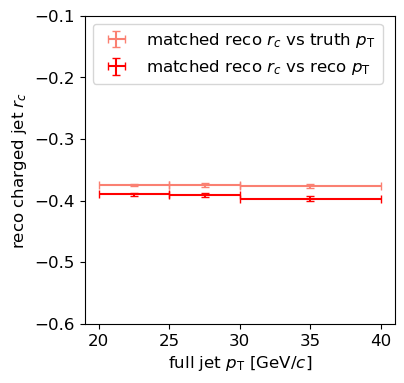

In [20]:
fig=plt.figure(figsize=(4,4))
plt.errorbar([22.5, 27.5, 35], rc_match_bs_vs_pt_array[1:-1], xerr=[2.5, 2.5, 5], yerr=rc_err_match_bs_vs_pt_array[1:-1], capsize=3, color='salmon', ls='none', label='matched reco $r_c$ vs truth $p_{\mathrm{T}}$')
plt.errorbar([22.5, 27.5, 35], rc_match_bs_vs_pts_array[1:-1], xerr=[2.5, 2.5, 5], yerr=rc_err_match_bs_vs_pts_array[1:-1], capsize=3, color='r', ls='none', label='matched reco $r_c$ vs reco $p_{\mathrm{T}}$')
plt.xlabel('full jet $p_{\mathrm{T}}$ [GeV$/c$]')
plt.axhline(y=0.0, color='grey', linestyle='--')
plt.ylabel('reco charged jet $r_c$')
plt.ylim(-0.6,-0.1)
plt.legend(loc='upper left')

In [21]:
b_match_array = []
for i in range(0,5):
    df_match_pts = df_match_pts_array[i]
    y_reco,yerr_reco,x = calc_hist(df_match_pts[ob+'s'], bins=np.arange(range_low,range_high+(range_high-range_low)/bins, (range_high-range_low)/bins), weights=df_match_pts['ws'], density=True)
    b_match_array.append(y_reco/sum(y_reco))
    print(y_reco/sum(y_reco))

[0.69657363 0.30342637]
[0.69483829 0.30516171]
[0.69578272 0.30421728]
[0.69850087 0.30149913]
[0.6980483 0.3019517]


In [22]:
binedges=[5,10,15,20,25,30,40,60]
match_fake, x = np.histogram(df_allreco['pts'], bins=binedges, weights=df_allreco['ws'])
match, _ = np.histogram(df_allreco[(df_allreco.pt!=-9) & (df_allreco.b!=-9) & (df_allreco.distance1<0.02) & (df_allreco.distance2<0.02)]['pts'], bins=binedges, weights=df_allreco[(df_allreco.pt!=-9) & (df_allreco.b!=-9) & (df_allreco.distance1<0.02) & (df_allreco.distance2<0.02)]['ws'])
eff4 = match/match_fake

/tmp/ipykernel_608439/4101531506.py:4: RuntimeWarning: invalid value encountered in divide
  eff4 = match/match_fake


In [23]:
fake_rate_array = np.ones(5)-eff4[2:7]
fake_rate_array

array([0.29936704, 0.24871283, 0.22295968, 0.20754411, 0.19886014])

$r_c$ correction is not needed

In [24]:
rc_match_b_vs_pt_array = []
rc_err_match_b_vs_pt_array = []
for i in range(0, len(df_match_pt_array)):
    rc_match_b_vs_pt_array.append(getRcAndErr(df_match_pt_array[i], 'b')[0])
    rc_err_match_b_vs_pt_array.append(getRcAndErr(df_match_pt_array[i], 'b')[1])

Text(20, -0.2, '$p$+$p$ $\\sqrt{s}=200$ GeV\nanti-$k_{\\mathrm{T}}$ jets, $R=0.4$')

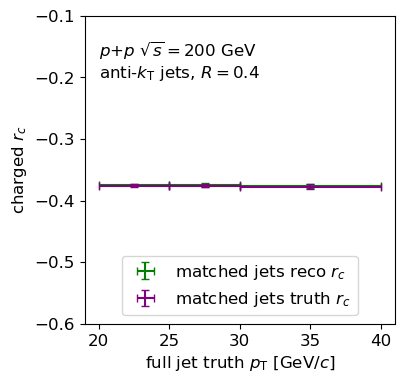

In [25]:
fig=plt.figure(figsize=(4,4))
plt.errorbar([22.5, 27.5, 35], rc_match_bs_vs_pt_array[1:-1], xerr=[2.5, 2.5, 5], yerr=rc_err_match_bs_vs_pt_array[1:-1], capsize=3, color='g', ls='none', label='matched jets reco $r_c$')
plt.errorbar([22.5, 27.5, 35], rc_match_b_vs_pt_array[1:-1], xerr=[2.5, 2.5, 5], yerr=rc_err_match_b_vs_pt_array[1:-1], capsize=3, color='purple', ls='none', label='matched jets truth $r_c$')
plt.xlabel('full jet truth $p_{\mathrm{T}}$ [GeV$/c$]')
plt.ylabel('charged $r_c$')
plt.ylim(-0.6,-0.1)
plt.legend(loc='lower center')
plt.text(20, -0.2, '$p$+$p$ $\sqrt{s}=200$ GeV\nanti-$k_{\mathrm{T}}$ jets, $R=0.4$')
#plt.title('Matching cut: truth pT > 5 GeV, truth Nch > 2, reco Nch > 2, dR(truth,reco) < 0.02')

In [26]:
print(sum(df_match[(df_match.bs!=df_match.b)]['w'])/sum(df_match['w']))

0.0013697919721684167


In [27]:
print(sum(df_match[(df_match.bs!=df_match.b)&(df_match.pt>20)&(df_match.pts>15)]['w'])/sum(df_match[(df_match.pt>20)&(df_match.pts>15)]['w']))

0.002373221670767629


In [28]:
print(rc_match_bs_vs_pt_array)
print(rc_match_b_vs_pt_array)

[-0.3900275492984042, -0.37487819966796565, -0.3750389173995791, -0.3759700347977471, -0.36352610809776903]
[-0.39054912522841234, -0.3756404113018331, -0.37591715579758905, -0.37727022512723885, -0.3664382843407736]


Process data

In [29]:
observables1 = ['pt','b']
file = uproot.open('/gpfs/gibbs/project/havener/ys668/rc/data0613_chargedrc.root')
tree = file["ResultTree"].arrays(observables1, library='np')
df_data = pd.DataFrame(np.transpose(np.array((np.concatenate(tree['pt']),np.concatenate(tree['b'])))), columns=["pts","bs"])
df_data = applyCut(df_data, 'pts>15 and bs!=-9 and bs!=0')

In [30]:
df_data_pts_array = [ df_data[(df_data.pts>15) & (df_data.pts<20)],\
                       df_data[(df_data.pts>20) & (df_data.pts<25)],\
                       df_data[(df_data.pts>25) & (df_data.pts<30)],\
                       df_data[(df_data.pts>30) & (df_data.pts<40)],\
                       df_data[(df_data.pts>40) & (df_data.pts<60)]  ]

In [31]:
def getRcAndErrAndN(df, ob):
    if (ob == 'bs'):
        nos = df[df.bs==-1].shape[0]
        nss = df[df.bs==+1].shape[0]
    else:
        print('Double check the input observable name!')
    rc = (nss-nos)/(nss+nos)
    p = nss/(nss+nos)
    n = nss+nos
    rc_err = 2*np.sqrt(p*(1-p)/n)
    return rc, rc_err, n

In [32]:
rc_data_bs_vs_pts_array = []
rc_err_data_bs_vs_pts_array = []
for i in range(0, len(df_data_pts_array)):
    rc_data_bs_vs_pts_array.append(getRcAndErrAndN(df_data_pts_array[i], 'bs')[0])
    rc_err_data_bs_vs_pts_array.append(getRcAndErrAndN(df_data_pts_array[i], 'bs')[1])

In [33]:
b_data_array = []
for i in range(0,5):
    df_data_pts = df_data_pts_array[i]
    y_reco,yerr_reco,x = calc_hist(df_data_pts['bs'], bins=np.arange(range_low,range_high+(range_high-range_low)/bins, (range_high-range_low)/bins))
    b_data_array.append(y_reco)

# 1. Mistagged subtraction

In [34]:
def getMatchedCountAndErr(data, fake_rate, fake_dist):
    corrected = data - sum(data) * fake_rate * fake_dist
    err = np.sqrt(corrected)
    return corrected, err

In [16]:
#fake_rate_array = np.array([0.29936704, 0.24871283, 0.22295968, 0.20754411, 0.19886014])
#b_fake_array = np.array([[0.61905176, 0.38094824],[0.61242198, 0.38757802],[0.60408262, 0.39591738],[0.5976935, 0.4023065],[0.59006909, 0.40993091]])

In [35]:
b_fakesubtracted_array = []
b_fakesubtractederr_array = []
rc1_array = []
rc1_err_array = []
for i in range(0,5):
    print(i)
    print(b_data_array[i])
    #print(getRc(data_array[i]))
    b_fakesubtracted, b_fakesubtractederr = getMatchedCountAndErr(b_data_array[i], fake_rate_array[i], b_fake_array[i])
    b_fakesubtracted_array.append(b_fakesubtracted)
    b_fakesubtractederr_array.append(b_fakesubtractederr)
    print(b_fakesubtracted)
    print(b_fakesubtractederr)
    nos = b_fakesubtracted[0]
    nss = b_fakesubtracted[1]
    n = nos + nss
    p = nss / n
    rc1 = (nss-nos) / (nss+nos)
    rc1_array.append(rc1)
    rc1_err_array.append( 2*np.sqrt(p*(1-p)/n) )

0
[337314. 178144.]
[242443.27365037 118703.58916847]
[492.38528984 344.53387231]
1
[72379. 38554.]
[55558.36793239 27784.17172085]
[235.70822627 166.68584739]
2
[16450.  8688.]
[13073.07860459  6460.16084997]
[114.33756428  80.37512582]
3
[4758. 2573.]
[3852.60398209 1956.89016356]
[62.06934817 44.23675128]
4
[334. 153.]
[276.88034881 113.27476485]
[16.63972202 10.64306182]


In [36]:
print(rc_data_bs_vs_pts_array)

[-0.3087933449476, -0.3049137767841851, -0.30877555891479036, -0.2980493793479744, -0.37166324435318276]


Text(20, -0.2, '$p$+$p$ $\\sqrt{s}=200$ GeV\nanti-$k_{\\mathrm{T}}$ jets, $R=0.4$')

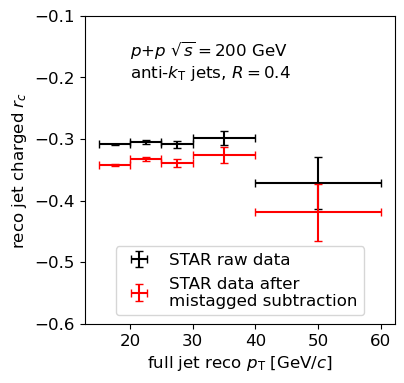

In [37]:
fig=plt.figure(figsize=(4,4))
plt.errorbar([17.5, 22.5, 27.5, 35, 50], rc_data_bs_vs_pts_array, xerr=[2.5, 2.5, 2.5, 5, 10], yerr=rc_err_data_bs_vs_pts_array, capsize=3, color='k', ls='none', label='STAR raw data')
plt.errorbar([17.5, 22.5, 27.5, 35, 50], rc1_array, xerr=[2.5, 2.5, 2.5, 5, 10], yerr=rc1_err_array, capsize=3, color='r', ls='none', label='STAR data after\nmistagged subtraction')
plt.xlabel('full jet reco $p_{\mathrm{T}}$ [GeV$/c$]')
plt.ylabel('reco jet charged $r_c$')
plt.ylim(-0.6,-0.1)
plt.legend(loc='lower center')
plt.text(20, -0.2, '$p$+$p$ $\sqrt{s}=200$ GeV\nanti-$k_{\mathrm{T}}$ jets, $R=0.4$')

# 2. $p_T$ correction

In [38]:
reweight_array = []
for i in range(0,5):
    reweight = (b_fakesubtracted_array[i]/sum(b_fakesubtracted_array[i]))/(b_match_array[i]/sum(b_match_array[i]))
    reweight_array.append(reweight)

In [39]:
reweight_array

[array([0.96373862, 1.08324499]),
 array([0.95939844, 1.09244777]),
 array([0.96190007, 1.08713927]),
 array([0.94939972, 1.11722866]),
 array([1.01664506, 0.96152014])]

([], [])

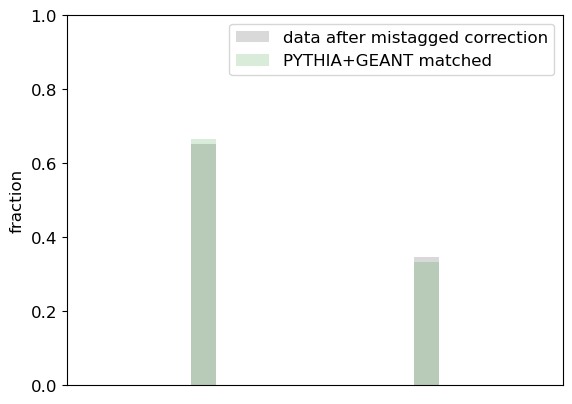

In [40]:
x = np.array([-0.5, 0.5])
plt.hist(x, weights=b_data_array[1]/sum(b_data_array[1]), color='k', alpha=0.15, label='data after mistagged correction')
plt.hist(x, weights=b_fakesubtracted_array[1]/sum(b_fakesubtracted_array[1]), ls='none', color='g', alpha=0.15, label='PYTHIA+GEANT matched')
#plt.errorbar(x+np.array([0.05,-0.05]), b_data_array[1][0]/sum(b_data_array[1]), yerr=y1err_array[0]/sum(b_data_array[1]), capsize=3, color='k', ls='none')
#plt.errorbar(x+np.array([0.05,-0.05]), b_fakesubtracted_array[1][0]/sum(b_fakesubtracted_array[1]), yerr=y1err_pythia_array[0]/sum(b_fakesubtracted_array[1]), capsize=3, color='g', ls='none')
plt.legend(fontsize=12)
plt.ylabel('fraction')
plt.xlim(range_low,range_high)
plt.ylim(bottom=0)
plt.xlim(-1,1)
plt.ylim(0,1)
plt.xlabel('')
plt.xticks([])

Reweight PYTHIA6+GEANT

In [41]:
r = []
for i in range(0, df_match.shape[0]):
    if (df_match.iloc[i]['pts'] > 15 and df_match.iloc[i]['pts'] < 20):
        if (df_match.iloc[i]['bs']==-1):
            r.append(reweight_array[0][0])
        else:
            r.append(reweight_array[0][1])
    elif (df_match.iloc[i]['pts'] > 20 and df_match.iloc[i]['pts'] < 25):
        if (df_match.iloc[i]['bs']==-1):
            r.append(reweight_array[1][0])
        else:
            r.append(reweight_array[1][1])
    elif (df_match.iloc[i]['pts'] > 25 and df_match.iloc[i]['pts'] < 30):
        if (df_match.iloc[i]['bs']==-1):
            r.append(reweight_array[2][0])
        else:
            r.append(reweight_array[2][1])
    elif (df_match.iloc[i]['pts'] > 30 and df_match.iloc[i]['pts'] < 40):
        if (df_match.iloc[i]['bs']==-1):
            r.append(reweight_array[3][0])
        else:
            r.append(reweight_array[3][1])
    elif (df_match.iloc[i]['pts'] > 40 and df_match.iloc[i]['pts'] < 60):
        if (df_match.iloc[i]['bs']==-1):
            r.append(reweight_array[4][0])
        else:
            r.append(reweight_array[4][1])
    else:
        r.append(1)
        print("anomaly reco pT:", df_match.iloc[i]['pts'])
df_match['r'] = r #

anomaly reco pT: 64.71016459194377
anomaly reco pT: 60.153276062896694
anomaly reco pT: 62.853705443277754
anomaly reco pT: 62.96298659444578
anomaly reco pT: 60.497728730756755
anomaly reco pT: 60.467066272681684
anomaly reco pT: 64.14492779876475
anomaly reco pT: 60.89421353610575
anomaly reco pT: 65.35667922469173
anomaly reco pT: 62.63427678982773
anomaly reco pT: 60.21434194892271
anomaly reco pT: 62.15032283200955
anomaly reco pT: 60.27780299483247
anomaly reco pT: 61.03197986884235
anomaly reco pT: 60.25483540234041
anomaly reco pT: 63.99508646678217
anomaly reco pT: 61.56890722000404
anomaly reco pT: 60.8697641572812
anomaly reco pT: 64.23631221912824
anomaly reco pT: 63.19369788337173
anomaly reco pT: 60.96653998630141
anomaly reco pT: 62.746029305931756
anomaly reco pT: 65.45530859825888
anomaly reco pT: 60.03476303183356
anomaly reco pT: 63.085829497123754
anomaly reco pT: 66.83963074901102
anomaly reco pT: 61.03609940388197
anomaly reco pT: 70.61911542903617
anomaly reco pT

anomaly reco pT: 61.37885697371845
anomaly reco pT: 61.45938905164215
anomaly reco pT: 60.16641125403288
anomaly reco pT: 60.09958144920835
anomaly reco pT: 60.511466054485055
anomaly reco pT: 62.350066426895815
anomaly reco pT: 66.11940247976565
anomaly reco pT: 62.15143279465398
anomaly reco pT: 60.697240773348895
anomaly reco pT: 61.79922547972766
anomaly reco pT: 62.11664288908429
anomaly reco pT: 66.38356449440559
anomaly reco pT: 70.6974465514885
anomaly reco pT: 62.49202362716819
anomaly reco pT: 61.065188221162096
anomaly reco pT: 61.23578848561933
anomaly reco pT: 61.52889434809697
anomaly reco pT: 60.31175466428895
anomaly reco pT: 63.22603510311757
anomaly reco pT: 60.18760080128897
anomaly reco pT: 62.83126138185055
anomaly reco pT: 61.152388176492224
anomaly reco pT: 63.75458910527901
anomaly reco pT: 68.07779701999323
anomaly reco pT: 60.92194379917718
anomaly reco pT: 60.93417972296193
anomaly reco pT: 61.33390390171952
anomaly reco pT: 61.446439875350215
anomaly reco pT

anomaly reco pT: 76.15786384596164
anomaly reco pT: 61.75583943405304
anomaly reco pT: 63.910930106712584
anomaly reco pT: 61.50802846399111
anomaly reco pT: 60.100454882871034
anomaly reco pT: 62.12533305728589
anomaly reco pT: 63.18755753863549
anomaly reco pT: 60.55812705404159
anomaly reco pT: 61.28085631237634
anomaly reco pT: 61.477432875243345
anomaly reco pT: 60.488095763928925
anomaly reco pT: 68.54885901919411
anomaly reco pT: 61.50396984848846
anomaly reco pT: 64.2182142798535
anomaly reco pT: 69.73367420432969
anomaly reco pT: 61.027595087508125
anomaly reco pT: 69.64749622782676
anomaly reco pT: 60.80583130708745
anomaly reco pT: 63.75691841415262
anomaly reco pT: 62.728856238000006
anomaly reco pT: 61.422837501199396
anomaly reco pT: 63.19510727748455
anomaly reco pT: 69.17229053514693
anomaly reco pT: 63.03810647468715
anomaly reco pT: 65.11635047674382
anomaly reco pT: 62.7859012143824
anomaly reco pT: 62.68461884512906
anomaly reco pT: 62.915869267031155
anomaly reco p

anomaly reco pT: 65.25033525577705
anomaly reco pT: 61.76350377269977
anomaly reco pT: 67.91261516206957
anomaly reco pT: 64.18896871067179
anomaly reco pT: 61.55566986656164
anomaly reco pT: 61.013202658559315
anomaly reco pT: 66.46683297420948
anomaly reco pT: 60.719874837864914
anomaly reco pT: 63.323007001359706
anomaly reco pT: 61.75751789795584
anomaly reco pT: 65.47874514245692
anomaly reco pT: 63.833226056318395
anomaly reco pT: 65.86571741812644
anomaly reco pT: 61.25108554868977
anomaly reco pT: 61.947579640882736
anomaly reco pT: 63.46254812809013
anomaly reco pT: 62.96891790372958
anomaly reco pT: 64.35138414682795
anomaly reco pT: 64.48172194800236
anomaly reco pT: 61.26632928367613
anomaly reco pT: 63.2261305431496
anomaly reco pT: 61.77634558122546
anomaly reco pT: 60.86607307973257
anomaly reco pT: 60.21395499719272
anomaly reco pT: 60.09408616047344
anomaly reco pT: 60.99685047564388
anomaly reco pT: 60.16363338769977
anomaly reco pT: 63.69926317750572
anomaly reco pT:

anomaly reco pT: 60.01648379395155
anomaly reco pT: 64.14932283185601
anomaly reco pT: 61.240900363557195
anomaly reco pT: 60.39707499656056
anomaly reco pT: 61.99196169405341
anomaly reco pT: 60.62075385730599
anomaly reco pT: 61.14995283043609
anomaly reco pT: 66.04902795304733
anomaly reco pT: 60.9882253190428
anomaly reco pT: 66.7477555786966
anomaly reco pT: 61.708920284156285
anomaly reco pT: 64.36438487503408
anomaly reco pT: 62.94062266284301
anomaly reco pT: 62.44423781464371
anomaly reco pT: 75.46724224373281
anomaly reco pT: 61.80903146481187
anomaly reco pT: 62.968781806216505
anomaly reco pT: 62.13383225030382
anomaly reco pT: 66.75514905802402
anomaly reco pT: 66.14452877031708
anomaly reco pT: 63.09405627123977
anomaly reco pT: 64.90408598375983
anomaly reco pT: 63.48728395117119
anomaly reco pT: 61.28346182911763
anomaly reco pT: 66.20971847276358
anomaly reco pT: 60.79420789744857
anomaly reco pT: 61.510335938526346
anomaly reco pT: 63.60463563764089
anomaly reco pT: 6

anomaly reco pT: 61.96069542684406
anomaly reco pT: 61.08044654494434
anomaly reco pT: 61.09486273833345
anomaly reco pT: 61.619816823255825
anomaly reco pT: 60.1205165345292
anomaly reco pT: 65.54303934620583
anomaly reco pT: 61.85195587271151
anomaly reco pT: 62.79148753043836
anomaly reco pT: 65.45394705223177
anomaly reco pT: 60.47310394891137
anomaly reco pT: 60.69591432542661
anomaly reco pT: 73.17949617801028
anomaly reco pT: 61.87642099724723
anomaly reco pT: 62.033255571884375
anomaly reco pT: 64.2315669762808
anomaly reco pT: 65.90115509233549
anomaly reco pT: 62.01507656506754
anomaly reco pT: 64.34097510153335
anomaly reco pT: 66.61530082068789
anomaly reco pT: 63.67323508181137
anomaly reco pT: 62.32187202592208
anomaly reco pT: 67.88504705434883
anomaly reco pT: 71.60937468564357
anomaly reco pT: 60.559015970087586
anomaly reco pT: 60.95447512822861
anomaly reco pT: 61.792050719662605
anomaly reco pT: 63.839684969398476
anomaly reco pT: 70.22762010076262
anomaly reco pT: 

... (42 outputs left out)

anomaly reco pT: 62.89429166096696
anomaly reco pT: 63.526915626256645
anomaly reco pT: 62.903646433743454
anomaly reco pT: 62.24583742968815
anomaly reco pT: 60.980579575795296
anomaly reco pT: 67.73686201808923
anomaly reco pT: 63.38584788803176
anomaly reco pT: 60.066299888070375
anomaly reco pT: 61.02399578604567
anomaly reco pT: 61.446595656916166
anomaly reco pT: 60.392823857397325
anomaly reco pT: 61.78311015605327
anomaly reco pT: 63.783428361486536
anomaly reco pT: 60.363202280530174
anomaly reco pT: 61.650299706987
anomaly reco pT: 62.362774067837506
anomaly reco pT: 60.6744275692727
anomaly reco pT: 60.430477638928
anomaly reco pT: 61.71315311098516
anomaly reco pT: 60.85945754578086
anomaly reco pT: 60.06862333944258
anomaly reco pT: 60.796577602152006
anomaly reco pT: 60.13963615109777
anomaly reco pT: 61.97707944317426
anomaly reco pT: 61.13605801618717
anomaly reco pT: 60.36267681037764
anomaly reco pT: 60.22971271220489
anomaly reco pT: 74.64295382467226
anomaly reco pT

anomaly reco pT: 61.476661485146
anomaly reco pT: 61.96365584249061
anomaly reco pT: 60.23695838987487
anomaly reco pT: 71.60701002835559
anomaly reco pT: 60.37688101328152
anomaly reco pT: 63.56514320295907
anomaly reco pT: 61.5810083062782
anomaly reco pT: 68.53923997112858
anomaly reco pT: 62.225501219032466
anomaly reco pT: 61.09090956196156
anomaly reco pT: 63.23312395465088
anomaly reco pT: 65.96302798676528
anomaly reco pT: 61.09552947718905
anomaly reco pT: 61.17343047347276
anomaly reco pT: 61.98946986641298
anomaly reco pT: 60.4943369207584
anomaly reco pT: 61.115651624121156
anomaly reco pT: 61.084035050284974
anomaly reco pT: 60.04634532820712
anomaly reco pT: 60.76288847004648
anomaly reco pT: 60.46021517963606
anomaly reco pT: 61.54397139009227
anomaly reco pT: 63.87569944102856
anomaly reco pT: 61.143372093719364
anomaly reco pT: 62.17458566387349
anomaly reco pT: 60.72446398534614
anomaly reco pT: 61.35709356965971
anomaly reco pT: 67.00331888979352
anomaly reco pT: 60.

anomaly reco pT: 65.68818700981551
anomaly reco pT: 61.54266411193234
anomaly reco pT: 62.55734250962372
anomaly reco pT: 65.15584289679612
anomaly reco pT: 60.529048010718526
anomaly reco pT: 72.08067145056319
anomaly reco pT: 61.43938629362258
anomaly reco pT: 60.77253707911821
anomaly reco pT: 63.15090440375343
anomaly reco pT: 62.47034835868642
anomaly reco pT: 63.896219063439055
anomaly reco pT: 68.42754005349394
anomaly reco pT: 62.1994543567997
anomaly reco pT: 62.072755225195145
anomaly reco pT: 69.50588256654626
anomaly reco pT: 62.185722171069855
anomaly reco pT: 61.0155207423607
anomaly reco pT: 61.66096513584184
anomaly reco pT: 62.72250015561953
anomaly reco pT: 60.84209105174485
anomaly reco pT: 60.651086849545436
anomaly reco pT: 62.146697609028664
anomaly reco pT: 62.27324868221418
anomaly reco pT: 68.87592018830773
anomaly reco pT: 67.50768458549679
anomaly reco pT: 65.62299859039155
anomaly reco pT: 62.67136030764501
anomaly reco pT: 62.32268438080635
anomaly reco pT:

/tmp/ipykernel_608439/3883675663.py:31: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_match['r'] = r #


In [42]:
def getRcAndErrNew(df, ob):
    if (ob == 'b'):
        nos = sum(np.array(df[df.b==-1]['w'])* np.array(df[df.b==-1]['r']))
        nss = sum(np.array(df[df.b==+1]['w'])* np.array(df[df.b==1]['r']))
    elif (ob == 'b_ch'):
        nos = sum(np.array(df[df.b_ch==-1]['w'])* np.array(df[df.b_ch==-1]['r']))
        nss = sum(np.array(df[df.b_ch==+1]['w'])* np.array(df[df.b_ch==1]['r']))
    elif (ob == 'bs'):
        nos = sum(np.array(df[df.bs==-1]['ws'])* np.array(df[df.bs==-1]['r']))
        nss = sum(np.array(df[df.bs==+1]['ws'])* np.array(df[df.bs==1]['r']))
    else:
        print('Double check the input observable name!')
    rc = (nss-nos)/(nss+nos)
    p = nss/(nss+nos)
    w_array = np.unique(df['w'])
    err2_array = []
    #variance_array_test = []
    for i in range(0, len(w_array)):
        if (ob == 'b'):
            p = sum(np.array(df[(df.w == w_array[i]) & (df.b==+1)]['w']) * np.array(df[(df.w == w_array[i]) & (df.b==+1)]['r'])) / sum(np.array(df[df.w == w_array[i]]['w']) * np.array(df[df.w == w_array[i]]['r']))
        elif (ob == 'b_ch'):
            p = sum(np.array(df[(df.w == w_array[i]) & (df.b_ch==+1)]['w']) * np.array(df[(df.w == w_array[i]) & (df.b_ch==+1)]['r'])) / sum(np.array(df[df.w == w_array[i]]['w'] * df[df.w == w_array[i]]['r']))         
        elif (ob == 'bs'):
            p = sum(np.array(df[(df.w == w_array[i]) & (df.bs==+1)]['w']) * np.array(df[(df.w == w_array[i]) & (df.bs==+1)]['r'])) / sum(np.array(df[df.w == w_array[i]]['ws'] * df[df.w == w_array[i]]['r']))
        else:
            print('Double check the input observable name!')        
        variance = p*(1-p)/df[df.w == w_array[i]].shape[0]
        #print(variance)
        #variance_array_test.append(variance)
        w = sum(df[df.w == w_array[i]]['w'])/sum(df['w'])
        err2_array.append ( w**2*variance )
    #print(variance_array_test)
    rc_err = 2*np.sqrt(sum(err2_array))
    #print(n)
    return rc, rc_err

In [43]:
df_match_pt_array = [ df_match[(df_match.pt>15) & (df_match.pt<20)],\
                       df_match[(df_match.pt>20) & (df_match.pt<25)],\
                       df_match[(df_match.pt>25) & (df_match.pt<30)],\
                       df_match[(df_match.pt>30) & (df_match.pt<40)],\
                       df_match[(df_match.pt>40) & (df_match.pt<60)] ]
df_match_pts_array = [ df_match[(df_match.pts>15) & (df_match.pts<20)],\
                       df_match[(df_match.pts>20) & (df_match.pts<25)],\
                       df_match[(df_match.pts>25) & (df_match.pts<30)],\
                       df_match[(df_match.pts>30) & (df_match.pts<40)],\
                       df_match[(df_match.pts>40) & (df_match.pts<60)]  ]

In [44]:
rc_match_bs_vs_pt_array = []
rc_err_match_bs_vs_pt_array = []
for i in range(0, len(df_match_pt_array)):
    rc_match_bs_vs_pt_array.append(getRcAndErrNew(df_match_pt_array[i], 'bs')[0])
    rc_err_match_bs_vs_pt_array.append(getRcAndErrNew(df_match_pt_array[i], 'bs')[1])
rc_match_bs_vs_pts_array_rw = []
rc_err_match_bs_vs_pts_array_rw = []
for i in range(0, len(df_match_pts_array)):
    rc_match_bs_vs_pts_array_rw.append(getRcAndErrNew(df_match_pts_array[i], 'bs')[0])
    rc_err_match_bs_vs_pts_array_rw.append(getRcAndErrNew(df_match_pts_array[i], 'bs')[1])

Check that the reweighted embedding is the same as data

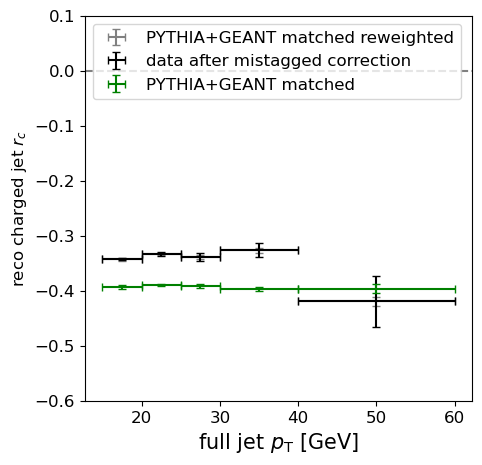

In [45]:
fig=plt.figure(figsize=(5,5))
plt.errorbar([17.5, 22.5, 27.5, 35, 50], rc_match_bs_vs_pts_array_rw, xerr=[2.5, 2.5, 2.5, 5, 10], yerr=rc_err_match_bs_vs_pts_array_rw, capsize=3, color='grey', ls='none', label='PYTHIA+GEANT matched reweighted')
plt.errorbar([17.5, 22.5, 27.5, 35, 50], rc1_array, xerr=[2.5, 2.5, 2.5, 5, 10], yerr=rc1_err_array, capsize=3, color='k', ls='none', label='data after mistagged correction')
plt.errorbar([17.5, 22.5, 27.5, 35, 50], rc_match_bs_vs_pts_array, xerr=[2.5, 2.5, 2.5, 5, 10], yerr=rc_err_match_bs_vs_pts_array, capsize=3, color='g', ls='none', label='PYTHIA+GEANT matched')
plt.xlabel('full jet $p_{\mathrm{T}}$ [GeV]', fontsize=15)
plt.axhline(y=0.0, color='grey', linestyle='--')
plt.ylabel('reco charged jet $r_c$')
plt.ylim(-0.6,0.1)
plt.legend(loc='upper left')

In [46]:
print(rc_match_bs_vs_pts_array_rw)

[-0.3426298196703956, -0.3332535380735282, -0.33854690462132625, -0.32631306117019404, -0.4193347164630004]


Text(20, -0.25, 'STAR data\n$p$+$p$ $\\sqrt{s}=200$ GeV\nanti-$k_{\\mathrm{T}}$ jets, $R=0.4$')

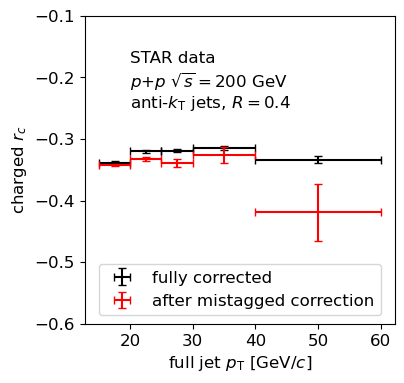

In [47]:
fig=plt.figure(figsize=(4,4))
plt.errorbar([17.5, 22.5, 27.5, 35, 50], rc_match_bs_vs_pt_array, xerr=[2.5, 2.5, 2.5, 5, 10], yerr=rc_err_match_bs_vs_pt_array, capsize=3, color='k', ls='none', label='fully corrected')
plt.errorbar([17.5, 22.5, 27.5, 35, 50], rc1_array, xerr=[2.5, 2.5, 2.5, 5, 10], yerr=rc1_err_array, capsize=3, color='r', ls='none', label='after mistagged correction')
plt.xlabel('full jet $p_{\mathrm{T}}$ [GeV$/c$]')
plt.ylabel('charged $r_c$')
plt.ylim(-0.6,-0.1)
plt.legend(loc='lower center')
plt.text(20, -0.25, 'STAR data\n$p$+$p$ $\sqrt{s}=200$ GeV\nanti-$k_{\mathrm{T}}$ jets, $R=0.4$')

Plot result

(-0.6, 0.1)

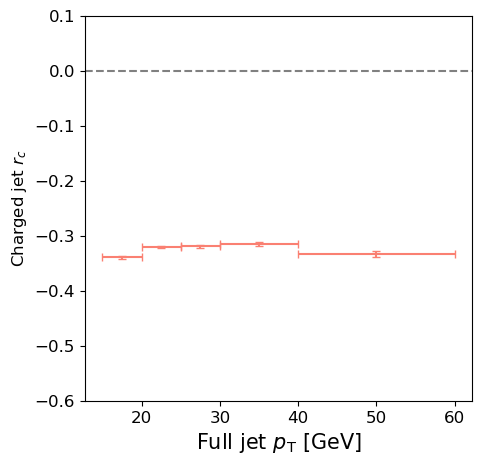

In [48]:
fig=plt.figure(figsize=(5,5))
plt.errorbar([17.5, 22.5, 27.5, 35, 50], rc_match_bs_vs_pt_array, xerr=[2.5, 2.5, 2.5, 5, 10], yerr=rc_err_match_bs_vs_pt_array, capsize=3, color='salmon', ls='none', label='sample 1 corrected')
#plt.errorbar([22.5, 27.5, 35], rc_match_bs_vs_pts_array[1:], xerr=[2.5, 2.5, 5], yerr=rc_err_match_bs_vs_pts_array[1:], capsize=3, color='r', ls='none', label='sample 1 corrected')
plt.xlabel('Full jet $p_{\mathrm{T}}$ [GeV]', fontsize=15)
plt.axhline(y=0.0, color='grey', linestyle='--')
plt.ylabel('Charged jet $r_c$')
plt.ylim(-0.6,0.1)
#plt.legend(loc='upper left', fontsize=15)

In [49]:
rc_match_bs_vs_pt_array

[-0.3389112603817457,
 -0.32028601537674556,
 -0.3191676473612476,
 -0.3143564592196943,
 -0.33358830600039374]

In [50]:
rc_err_match_bs_vs_pt_array

[0.0028789215820300153,
 0.0022479274574119927,
 0.0028089529671868215,
 0.003494015432857007,
 0.005275830926913249]